**Discente:** Laura Ribeiro Mota  
**RA:** 1016012  
**Disciplina:** Linguagens de Programação  
**Docente:** Alexandre Neves Louzada  
**Data:** 03/10/2026  

---

# Análise de Acidentes de Trânsito no Brasil

## 1. Introdução

Os acidentes de trânsito representam um importante problema relacionado à segurança viária e à saúde pública, podendo resultar em mortes, ferimentos, impactos econômicos, congestionamentos e sobrecarga dos sistemas de saúde.

Este projeto tem como objetivo realizar uma análise exploratória dos dados de acidentes de trânsito no Brasil entre os anos de 2015 e 2024, buscando identificar padrões temporais, geográficos e relacionados às características das ocorrências.

A análise busca investigar questões como:

- Quais estados apresentam maior número de acidentes?
- Quais tipos de acidentes são mais frequentes?
- Existem períodos do dia com maior ocorrência de acidentes?
- Houve aumento ou redução dos acidentes ao longo dos anos?
- Existe relação entre o volume de chuva e a ocorrência de acidentes?
- Quais regiões apresentam os maiores números de acidentes?
- Quais fatores parecem estar associados aos acidentes mais graves?

Ao final, os resultados obtidos serão apresentados em um dashboard interativo desenvolvido com Streamlit.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Conhecendo a base de dados

A base utilizada neste projeto contém dados simulados sobre acidentes de trânsito ocorridos no Brasil entre 2015 e 2024.

O conjunto de dados apresenta informações temporais e geográficas das ocorrências, além de características relacionadas aos acidentes, como tipo de acidente, período do dia, número de feridos e mortes, condições de chuva, visibilidade, quantidade de veículos envolvidos e nível de gravidade.

In [13]:
df = pd.read_csv("../dados/simulacao_acidentes_transito_brasil_tema27.csv")

In [14]:
df.head()

,ano,mes,data,regiao,uf,cidade,tipo_acidente,periodo_dia,acidentes,feridos,mortes,chuva_mm,visibilidade,veiculos_envolvidos,nivel_gravidade
0,2015,1,2015-01-01,Norte,AM,Manaus,Capotamento,Tarde,12,15,2,24.0,Boa,28,Moderado
1,2015,1,2015-01-01,Norte,PA,Belém,Atropelamento,Manhã,13,17,0,9.8,Ruim,30,Crítico
2,2015,1,2015-01-01,Norte,PA,Santarém,Capotamento,Tarde,18,12,0,50.4,Ruim,31,Leve
3,2015,1,2015-01-01,Norte,RO,Porto Velho,Atropelamento,Tarde,25,16,1,39.8,Boa,36,Grave
4,2015,1,2015-01-01,Norte,TO,Palmas,Atropelamento,Manhã,15,19,0,59.5,Boa,34,Grave


In [15]:
df.shape

(4440, 15)

In [16]:
df.columns

Index(['ano', 'mes', 'data', 'regiao', 'uf', 'cidade', 'tipo_acidente',
       'periodo_dia', 'acidentes', 'feridos', 'mortes', 'chuva_mm',
       'visibilidade', 'veiculos_envolvidos', 'nivel_gravidade'],
      dtype='str')

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4440 entries, 0 to 4439
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ano                  4440 non-null   int64  
 1   mes                  4440 non-null   int64  
 2   data                 4440 non-null   str    
 3   regiao               4440 non-null   str    
 4   uf                   4440 non-null   str    
 5   cidade               4440 non-null   str    
 6   tipo_acidente        4440 non-null   str    
 7   periodo_dia          4440 non-null   str    
 8   acidentes            4440 non-null   int64  
 9   feridos              4440 non-null   int64  
 10  mortes               4440 non-null   int64  
 11  chuva_mm             4440 non-null   float64
 12  visibilidade         4440 non-null   str    
 13  veiculos_envolvidos  4440 non-null   int64  
 14  nivel_gravidade      4440 non-null   str    
dtypes: float64(1), int64(6), str(8)
memory usage: 782

In [18]:
df.isnull().sum()

ano                    0
mes                    0
data                   0
regiao                 0
uf                     0
cidade                 0
tipo_acidente          0
periodo_dia            0
acidentes              0
feridos                0
mortes                 0
chuva_mm               0
visibilidade           0
veiculos_envolvidos    0
nivel_gravidade        0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.describe()

,ano,mes,acidentes,feridos,mortes,chuva_mm,veiculos_envolvidos
count,4440.000000,4440.000000,4440.000000,4440.000000,4440.000000,4440.000000,4440.000000
mean,2019.500000,6.500000,19.943018,11.964414,1.016892,30.010901,34.982883
std,2.872605,3.452441,4.361833,3.489771,1.006594,20.901492,5.868168
min,2015.000000,1.000000,6.000000,2.000000,0.000000,0.200000,15.000000
25%,2017.000000,3.750000,17.000000,9.750000,0.000000,14.800000,31.000000
50%,2019.500000,6.500000,20.000000,12.000000,1.000000,25.200000,35.000000
75%,2022.000000,9.250000,23.000000,14.000000,2.000000,40.300000,39.000000
max,2024.000000,12.000000,36.000000,27.000000,6.000000,197.400000,58.000000


In [21]:
df.info()
df.isnull().sum()
df.duplicated().sum()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4440 entries, 0 to 4439
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ano                  4440 non-null   int64  
 1   mes                  4440 non-null   int64  
 2   data                 4440 non-null   str    
 3   regiao               4440 non-null   str    
 4   uf                   4440 non-null   str    
 5   cidade               4440 non-null   str    
 6   tipo_acidente        4440 non-null   str    
 7   periodo_dia          4440 non-null   str    
 8   acidentes            4440 non-null   int64  
 9   feridos              4440 non-null   int64  
 10  mortes               4440 non-null   int64  
 11  chuva_mm             4440 non-null   float64
 12  visibilidade         4440 non-null   str    
 13  veiculos_envolvidos  4440 non-null   int64  
 14  nivel_gravidade      4440 non-null   str    
dtypes: float64(1), int64(6), str(8)
memory usage: 782

,ano,mes,acidentes,feridos,mortes,chuva_mm,veiculos_envolvidos
count,4440.000000,4440.000000,4440.000000,4440.000000,4440.000000,4440.000000,4440.000000
mean,2019.500000,6.500000,19.943018,11.964414,1.016892,30.010901,34.982883
std,2.872605,3.452441,4.361833,3.489771,1.006594,20.901492,5.868168
min,2015.000000,1.000000,6.000000,2.000000,0.000000,0.200000,15.000000
25%,2017.000000,3.750000,17.000000,9.750000,0.000000,14.800000,31.000000
50%,2019.500000,6.500000,20.000000,12.000000,1.000000,25.200000,35.000000
75%,2022.000000,9.250000,23.000000,14.000000,2.000000,40.300000,39.000000
max,2024.000000,12.000000,36.000000,27.000000,6.000000,197.400000,58.000000


## 3. Limpeza e preparação dos dados

Antes de realizar as análises, é necessário verificar a qualidade da base e preparar os dados para utilização.

Nesta etapa, serão analisados valores ausentes, registros duplicados, tipos de dados e possíveis inconsistências nas variáveis.

### Verificação da qualidade dos dados

A inspeção inicial da base demonstrou que todas as colunas possuem 4.440 valores preenchidos, não sendo identificados valores ausentes.

A verificação de duplicidade também não identificou registros completamente duplicados na base.

Em relação aos tipos de dados, as variáveis numéricas foram reconhecidas adequadamente. Entretanto, a coluna `data` foi inicialmente interpretada como texto (`str`), sendo necessária sua conversão para um formato de data.

In [22]:
df["data"] = pd.to_datetime(df["data"])

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4440 entries, 0 to 4439
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ano                  4440 non-null   int64         
 1   mes                  4440 non-null   int64         
 2   data                 4440 non-null   datetime64[us]
 3   regiao               4440 non-null   str           
 4   uf                   4440 non-null   str           
 5   cidade               4440 non-null   str           
 6   tipo_acidente        4440 non-null   str           
 7   periodo_dia          4440 non-null   str           
 8   acidentes            4440 non-null   int64         
 9   feridos              4440 non-null   int64         
 10  mortes               4440 non-null   int64         
 11  chuva_mm             4440 non-null   float64       
 12  visibilidade         4440 non-null   str           
 13  veiculos_envolvidos  4440 non-null   int64  

In [24]:
df["regiao"].unique()

<ArrowStringArray>
['Norte', 'Nordeste', 'Centro-Oeste', 'Sudeste', 'Sul']
Length: 5, dtype: str

In [25]:
df["uf"].unique()

<ArrowStringArray>
['AM', 'PA', 'RO', 'TO', 'BA', 'PE', 'CE', 'MA', 'PB', 'DF', 'GO', 'MT', 'MS',
 'SP', 'RJ', 'MG', 'ES', 'PR', 'SC', 'RS']
Length: 20, dtype: str

In [26]:
df["tipo_acidente"].unique()

<ArrowStringArray>
['Capotamento', 'Atropelamento', 'Saída de pista', 'Colisão']
Length: 4, dtype: str

In [27]:
df["periodo_dia"].unique()

<ArrowStringArray>
['Tarde', 'Manhã', 'Noite', 'Madrugada']
Length: 4, dtype: str

In [28]:
df["visibilidade"].unique()

<ArrowStringArray>
['Boa', 'Ruim', 'Muito ruim', 'Moderada']
Length: 4, dtype: str

In [29]:
df["nivel_gravidade"].unique()

<ArrowStringArray>
['Moderado', 'Crítico', 'Leve', 'Grave']
Length: 4, dtype: str

In [30]:
df["nivel_gravidade"].value_counts()

nivel_gravidade
Crítico     1154
Grave       1115
Moderado    1086
Leve        1085
Name: count, dtype: int64

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4440 entries, 0 to 4439
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ano                  4440 non-null   int64         
 1   mes                  4440 non-null   int64         
 2   data                 4440 non-null   datetime64[us]
 3   regiao               4440 non-null   str           
 4   uf                   4440 non-null   str           
 5   cidade               4440 non-null   str           
 6   tipo_acidente        4440 non-null   str           
 7   periodo_dia          4440 non-null   str           
 8   acidentes            4440 non-null   int64         
 9   feridos              4440 non-null   int64         
 10  mortes               4440 non-null   int64         
 11  chuva_mm             4440 non-null   float64       
 12  visibilidade         4440 non-null   str           
 13  veiculos_envolvidos  4440 non-null   int64  

In [33]:
df.duplicated().sum()

np.int64(0)

In [34]:
print("Regiões:")
print(df["regiao"].unique())

print("\nEstados:")
print(df["uf"].unique())

print("\nTipos de acidente:")
print(df["tipo_acidente"].unique())

print("\nPeríodos do dia:")
print(df["periodo_dia"].unique())

print("\nVisibilidade:")
print(df["visibilidade"].unique())

print("\nNíveis de gravidade:")
print(df["nivel_gravidade"].unique())

Regiões:
<ArrowStringArray>
['Norte', 'Nordeste', 'Centro-Oeste', 'Sudeste', 'Sul']
Length: 5, dtype: str

Estados:
<ArrowStringArray>
['AM', 'PA', 'RO', 'TO', 'BA', 'PE', 'CE', 'MA', 'PB', 'DF', 'GO', 'MT', 'MS',
 'SP', 'RJ', 'MG', 'ES', 'PR', 'SC', 'RS']
Length: 20, dtype: str

Tipos de acidente:
<ArrowStringArray>
['Capotamento', 'Atropelamento', 'Saída de pista', 'Colisão']
Length: 4, dtype: str

Períodos do dia:
<ArrowStringArray>
['Tarde', 'Manhã', 'Noite', 'Madrugada']
Length: 4, dtype: str

Visibilidade:
<ArrowStringArray>
['Boa', 'Ruim', 'Muito ruim', 'Moderada']
Length: 4, dtype: str

Níveis de gravidade:
<ArrowStringArray>
['Moderado', 'Crítico', 'Leve', 'Grave']
Length: 4, dtype: str


### Resultado da limpeza e preparação

Após a inspeção da base, não foram identificados valores ausentes nem registros completamente duplicados. As principais variáveis categóricas também apresentaram valores aparentemente padronizados, não sendo necessária a correção de nomenclaturas.

A principal transformação realizada nesta etapa foi a conversão da coluna `data`, inicialmente interpretada como texto, para o tipo `datetime`, permitindo sua utilização adequada em análises temporais.

Dessa forma, a base encontra-se preparada para as próximas etapas da análise.

## 4. Engenharia de atributos

A engenharia de atributos consiste na criação de novas variáveis a partir dos dados existentes, com o objetivo de ampliar as possibilidades de análise.

Neste projeto, a partir da coluna `data`, será criada a variável `dia_semana`, permitindo analisar a distribuição dos acidentes de acordo com o dia da semana.

In [35]:
df["dia_semana"] = df["data"].dt.day_name()

In [39]:
df[["data", "dia_semana"]].head(10)

,data,dia_semana
0,2015-01-01,Thursday
1,2015-01-01,Thursday
2,2015-01-01,Thursday
3,2015-01-01,Thursday
4,2015-01-01,Thursday
5,2015-01-01,Thursday
6,2015-01-01,Thursday
7,2015-01-01,Thursday
8,2015-01-01,Thursday
9,2015-01-01,Thursday


In [40]:
traducao_dias = {
    "Monday": "Segunda-feira",
    "Tuesday": "Terça-feira",
    "Wednesday": "Quarta-feira",
    "Thursday": "Quinta-feira",
    "Friday": "Sexta-feira",
    "Saturday": "Sábado",
    "Sunday": "Domingo"
}

df["dia_semana"] = df["dia_semana"].map(traducao_dias)

In [ ]:
df[["data", "dia_semana"]].head()

,data,dia_semana
0,2015-01-01,Quinta-feira
1,2015-01-01,Quinta-feira
2,2015-01-01,Quinta-feira
3,2015-01-01,Quinta-feira
4,2015-01-01,Quinta-feira


In [ ]:
df["dia_semana"].unique()

<ArrowStringArray>
[ 'Quinta-feira',       'Domingo',  'Quarta-feira',   'Sexta-feira',
 'Segunda-feira',        'Sábado',   'Terça-feira']
Length: 7, dtype: str

In [ ]:
df.shape

(4440, 16)

## 5. Análise Exploratória de Dados

Nesta etapa, será realizada a análise exploratória dos dados com o objetivo de identificar padrões relacionados à distribuição geográfica, evolução temporal, tipos de acidentes, períodos do dia e demais características das ocorrências.

As análises serão utilizadas para responder às perguntas orientadoras do projeto e servirão como base para a construção das visualizações e dos indicadores apresentados posteriormente no dashboard.

### 5.1 Análise por região

Nesta análise, os acidentes são agrupados de acordo com sua região, permitindo identificar quais regiões geográficas apresentam maior frequência na base analisada.

- #### Acidentes por região

In [ ]:
acidentes_por_regiao = (
    df.groupby("regiao")["acidentes"]
      .sum()
      .sort_values(ascending=False)
)

acidentes_por_regiao

regiao
Sudeste         31054
Nordeste        19207
Sul             14433
Centro-Oeste    12052
Norte           11801
Name: acidentes, dtype: int64

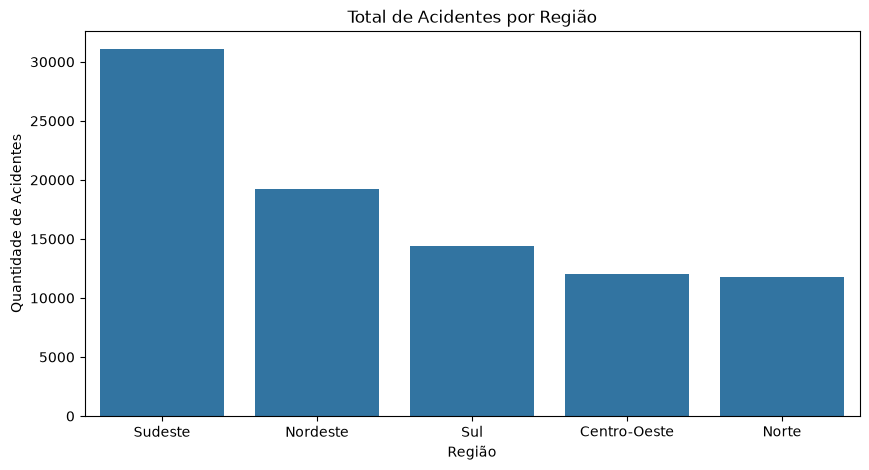

In [ ]:
## Gráfico acidentes por região

plt.figure(figsize=(10, 5))

sns.barplot(
    x=acidentes_por_regiao.index,
    y=acidentes_por_regiao.values
)

plt.title("Total de Acidentes por Região")
plt.xlabel("Região")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### Interpretação — Distribuição regional


A análise regional demonstra que a região Sudeste apresentou o maior número de acidentes na base analisada, totalizando 31.054 ocorrências. Em seguida, aparecem as regiões Nordeste, com 19.207 acidentes, e Sul, com 14.433.

As regiões Centro-Oeste e Norte apresentaram os menores totais, com 12.052 e 11.801 acidentes, respectivamente.

Os resultados indicam uma concentração maior de acidentes registrados na região Sudeste dentro da base analisada. Entretanto, esses valores representam números absolutos e não consideram fatores como população, extensão da malha viária ou quantidade de veículos de cada região.

### 5.2 Análise por estado

Nesta análise, os acidentes são agrupados de acordo com seu, permitindo identificar quais estados do Brasil apresentam maior frequência na base analisada.

- #### Acidentes por estado

In [52]:
acidentes_por_estado = (
    df.groupby("uf")["acidentes"]
      .sum()
      .sort_values(ascending=False)
)

acidentes_por_estado

uf
RJ    9633
ES    7203
MG    7159
SP    7059
PE    4885
GO    4847
RS    4827
BA    4808
PR    4807
SC    4799
PA    4761
CE    4705
MA    2434
DF    2423
MT    2399
RO    2385
MS    2383
PB    2375
AM    2352
TO    2303
Name: acidentes, dtype: int64

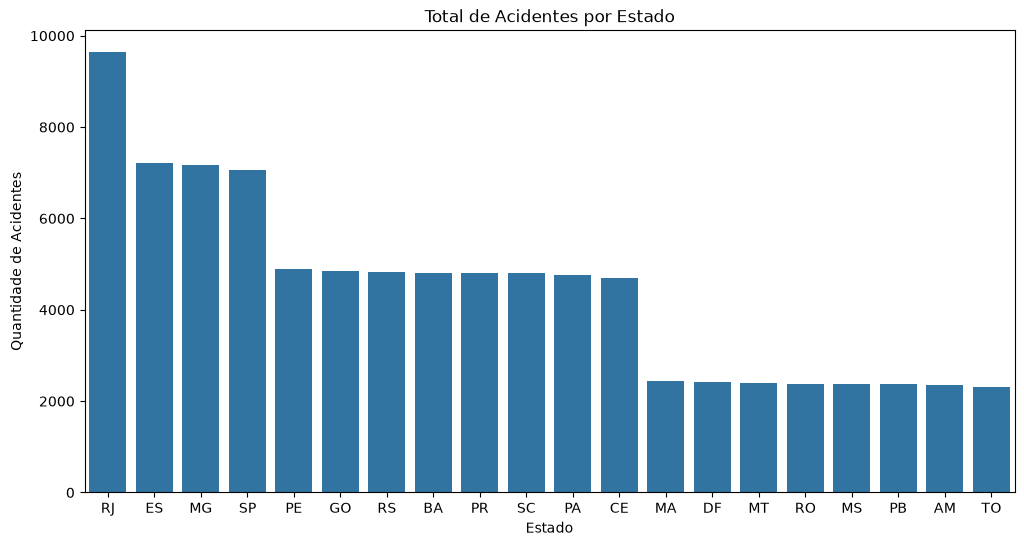

In [53]:
## Gráfico acidentes por estado

plt.figure(figsize=(12, 6))

sns.barplot(
    x=acidentes_por_estado.index,
    y=acidentes_por_estado.values
)

plt.title("Total de Acidentes por Estado")
plt.xlabel("Estado")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### Interpretação — Distribuição por estado

Na análise por estado, o Rio de Janeiro apresentou o maior número de acidentes registrados na base, com 9.633 ocorrências. Em seguida aparecem Espírito Santo, com 7.203, Minas Gerais, com 7.159, e São Paulo, com 7.059 acidentes.

Os quatro estados com maiores totais pertencem à região Sudeste, contribuindo para que essa região apresente o maior número absoluto de acidentes na análise regional.

É importante destacar que a comparação considera valores absolutos da base e não taxas proporcionais à população, frota de veículos ou extensão da malha viária de cada estado.

### 5.3 Análise de acidentes por tipo

Nesta análise, os acidentes são agrupados de acordo com sua classificação, permitindo identificar quais tipos de acidentes apresentam maior frequência na base analisada.

- #### Acidentes por tipo

In [54]:
acidentes_por_tipo = (
    df.groupby("tipo_acidente")["acidentes"]
      .sum()
      .sort_values(ascending=False)
)

acidentes_por_tipo

tipo_acidente
Atropelamento     23900
Saída de pista    22070
Colisão           21545
Capotamento       21032
Name: acidentes, dtype: int64

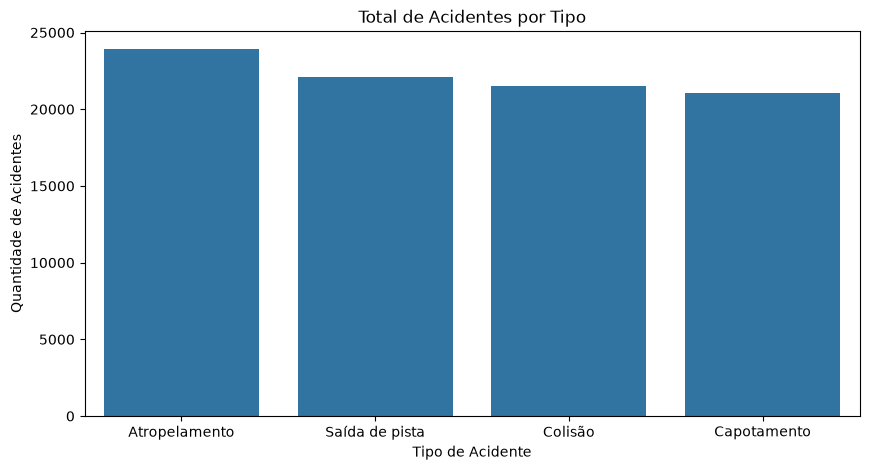

In [55]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=acidentes_por_tipo.index,
    y=acidentes_por_tipo.values
)

plt.title("Total de Acidentes por Tipo")
plt.xlabel("Tipo de Acidente")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### Interpretação — Tipo de acidente

A análise por tipo de acidente mostra que os atropelamentos apresentaram o maior total de ocorrências na base analisada, com 23.900 acidentes.

Em seguida aparecem as saídas de pista, com 22.070 acidentes, as colisões, com 21.545, e os capotamentos, com 21.032.

Embora os atropelamentos ocupem a primeira posição, os totais entre as quatro categorias são relativamente próximos, indicando uma distribuição sem grande concentração em apenas um tipo de acidente.

### 5.4 Análise por período do dia

Nesta análise, os acidentes são agrupados de acordo com o período do dia que ocorreu, permitindo identificar quais períodos apresentam maior frequência na base analisada.

- #### Acidentes por período do dia

In [56]:
acidentes_por_periodo = (
    df.groupby("periodo_dia")["acidentes"]
      .sum()
      .sort_values(ascending=False)
)

acidentes_por_periodo

periodo_dia
Tarde        23186
Noite        22244
Manhã        21578
Madrugada    21539
Name: acidentes, dtype: int64

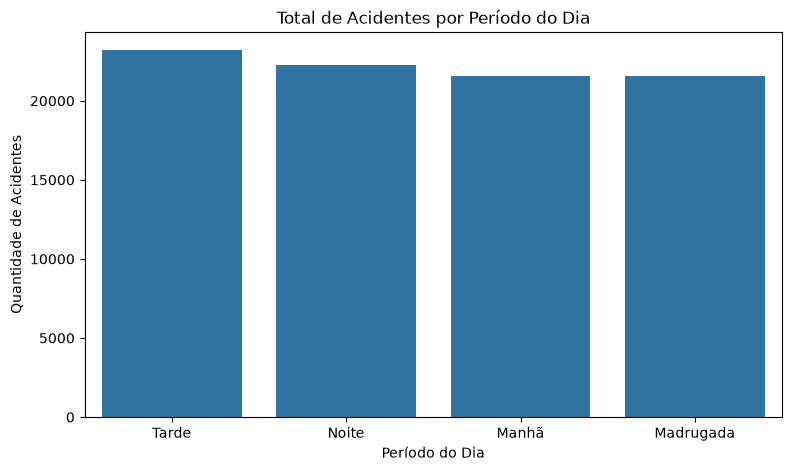

In [57]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=acidentes_por_periodo.index,
    y=acidentes_por_periodo.values
)

plt.title("Total de Acidentes por Período do Dia")
plt.xlabel("Período do Dia")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### Interpretação — Período do dia

A tarde apresentou o maior número de acidentes registrados na base, com 23.186 ocorrências.

Na sequência aparecem a noite, com 22.244 acidentes, a manhã, com 21.578, e a madrugada, com 21.539.

Apesar de a tarde apresentar o maior total, as diferenças entre os períodos do dia são relativamente pequenas. Portanto, os dados não indicam uma concentração extremamente elevada em um único período.

### 5.5 Evolução temporal dos acidentes

Nesta análise, os acidentes são agrupados de acordo com seu ano, permitindo identificar quais anos apresentam maior frequência na base analisada.

In [58]:
acidentes_por_ano = (
    df.groupby("ano")["acidentes"]
      .sum()
)

acidentes_por_ano

ano
2015    8870
2016    8862
2017    8903
2018    8896
2019    8788
2020    8766
2021    8863
2022    8832
2023    8905
2024    8862
Name: acidentes, dtype: int64

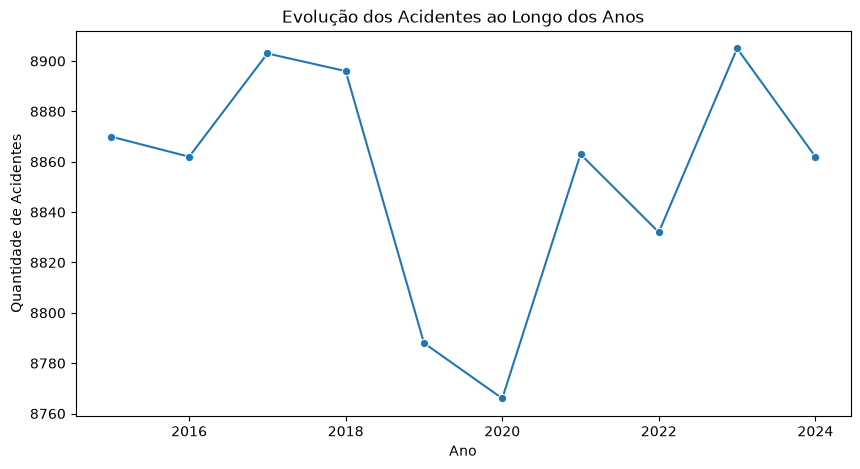

In [59]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=acidentes_por_ano.index,
    y=acidentes_por_ano.values,
    marker="o"
)

plt.title("Evolução dos Acidentes ao Longo dos Anos")
plt.xlabel("Ano")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### Interpretação — Evolução temporal

A análise da evolução temporal dos acidentes entre 2015 e 2024 mostra relativa estabilidade ao longo do período.

Os totais anuais permaneceram próximos entre si, variando de 8.766 acidentes, em 2020, a 8.905 acidentes, em 2023.

Não foi identificada uma tendência contínua de crescimento ou redução no número de acidentes. Em vez disso, os dados apresentam pequenas oscilações anuais, mantendo-se em uma faixa semelhante durante todo o período analisado.

Dessa forma, considerando a base utilizada, o comportamento dos acidentes ao longo dos anos pode ser caracterizado como estável.

### 5.6 Análise por dia da semana

Nesta análise, os acidentes são agrupados de acordo com o dia da semana, permitindo identificar quais dias da semana apresentam maior frequência na base analisada.
Para esta análise,antes de tudo, os dias foram ordenados para melhorar a disposição dos dados e facilitar a compreensão.

- #### Acidentes por dia da semana

In [60]:
acidentes_por_dia = (
    df.groupby("dia_semana")["acidentes"]
      .sum()
      .sort_values(ascending=False)
)

acidentes_por_dia

dia_semana
Sexta-feira      13932
Quarta-feira     13421
Domingo          13287
Segunda-feira    12685
Quinta-feira     12299
Terça-feira      11797
Sábado           11126
Name: acidentes, dtype: int64

In [61]:
ordem_dias = [
    "Segunda-feira",
    "Terça-feira",
    "Quarta-feira",
    "Quinta-feira",
    "Sexta-feira",
    "Sábado",
    "Domingo"
]

acidentes_por_dia_ordenado = (
    df.groupby("dia_semana")["acidentes"]
      .sum()
      .reindex(ordem_dias)
)

acidentes_por_dia_ordenado

dia_semana
Segunda-feira    12685
Terça-feira      11797
Quarta-feira     13421
Quinta-feira     12299
Sexta-feira      13932
Sábado           11126
Domingo          13287
Name: acidentes, dtype: int64

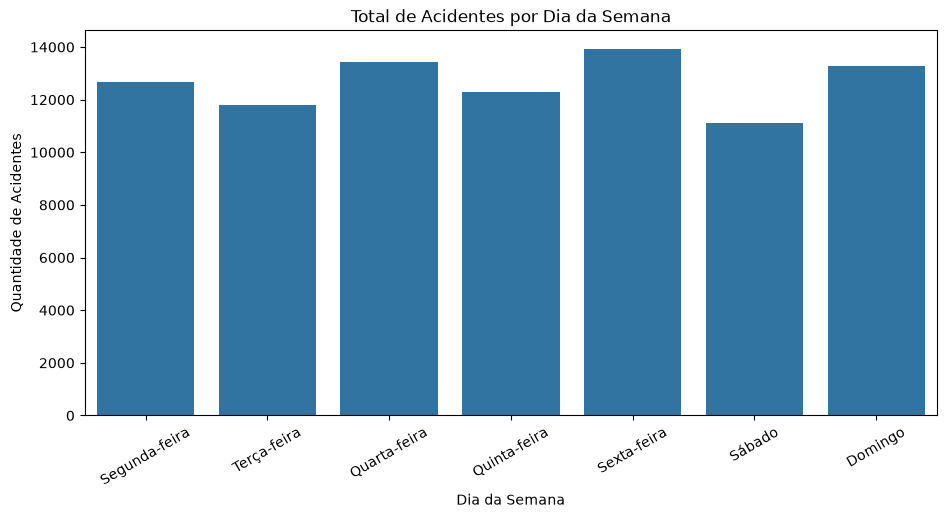

In [62]:
plt.figure(figsize=(11, 5))

sns.barplot(
    x=acidentes_por_dia_ordenado.index,
    y=acidentes_por_dia_ordenado.values
)

plt.title("Total de Acidentes por Dia da Semana")
plt.xlabel("Dia da Semana")
plt.ylabel("Quantidade de Acidentes")

plt.xticks(rotation=30)

plt.show()

### Interpretação — Dia da semana

A análise por dia da semana mostra que a sexta-feira apresentou o maior número de acidentes registrados na base, totalizando 13.932 ocorrências.

Em seguida aparecem a quarta-feira, com 13.421 acidentes, e o domingo, com 13.287. O sábado apresentou o menor total, com 11.126 acidentes.

Os resultados indicam variações entre os dias da semana, embora os acidentes estejam distribuídos ao longo de todos os dias. Considerando apenas os valores absolutos da base, a sexta-feira se destaca como o dia com maior número de ocorrências.

### 5.7 Análise por nível de gravidade

Nesta análise, os acidentes são agrupados de acordo com seu nível de gravidade, permitindo observar a distribuição das ocorrências entre as categorias leve, moderada, grave e crítica.

In [63]:
acidentes_por_gravidade = (
    df.groupby("nivel_gravidade")["acidentes"]
      .sum()
      .sort_values(ascending=False)
)

acidentes_por_gravidade

nivel_gravidade
Crítico     22886
Grave       22264
Leve        21730
Moderado    21667
Name: acidentes, dtype: int64

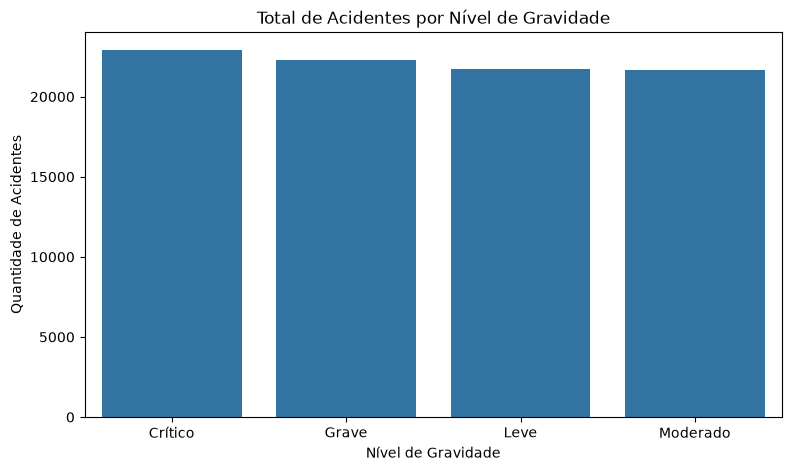

In [64]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=acidentes_por_gravidade.index,
    y=acidentes_por_gravidade.values
)

plt.title("Total de Acidentes por Nível de Gravidade")
plt.xlabel("Nível de Gravidade")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### 5.8 Totais gerais de acidentes, feridos e mortes

Nesta etapa, são calculados os totais gerais de acidentes, feridos e mortes registrados na base analisada.

Esses indicadores permitem dimensionar o volume das ocorrências e seus impactos, além de servirem como base para a construção dos KPIs que serão apresentados posteriormente no dashboard interativo.

In [65]:
total_acidentes = df["acidentes"].sum()
total_feridos = df["feridos"].sum()
total_mortes = df["mortes"].sum()

print("Total de acidentes:", total_acidentes)
print("Total de feridos:", total_feridos)
print("Total de mortes:", total_mortes)

Total de acidentes: 88547
Total de feridos: 53122
Total de mortes: 4515


### Interpretação — Totais gerais

A base analisada registra um total de 88.547 acidentes, 53.122 feridos e 4.515 mortes.

Esses valores fornecem uma visão geral da dimensão das ocorrências presentes no conjunto de dados e permitem observar não apenas a quantidade de acidentes, mas também suas consequências em termos de pessoas feridas e mortes registradas.

Os totais de acidentes e mortes também serão utilizados posteriormente como indicadores de destaque no dashboard.

### 5.9 Análise de mortes por nível de gravidade

Além de analisar a quantidade de acidentes em cada nível de gravidade, também é importante observar como as mortes estão distribuídas entre essas categorias.

Nesta análise, os registros são agrupados pelo nível de gravidade e é calculado o total de mortes associado a cada grupo, permitindo comparar o impacto das diferentes classificações de gravidade.

In [67]:
total_acidentes = df["acidentes"].sum()
total_feridos = df["feridos"].sum()
total_mortes = df["mortes"].sum()

print("Total de acidentes:", total_acidentes)
print("Total de feridos:", total_feridos)
print("Total de mortes:", total_mortes)

Total de acidentes: 88547
Total de feridos: 53122
Total de mortes: 4515


In [68]:
mortes_por_gravidade = (
    df.groupby("nivel_gravidade")["mortes"]
      .sum()
      .sort_values(ascending=False)
)

mortes_por_gravidade

nivel_gravidade
Crítico     1221
Leve        1124
Grave       1101
Moderado    1069
Name: mortes, dtype: int64

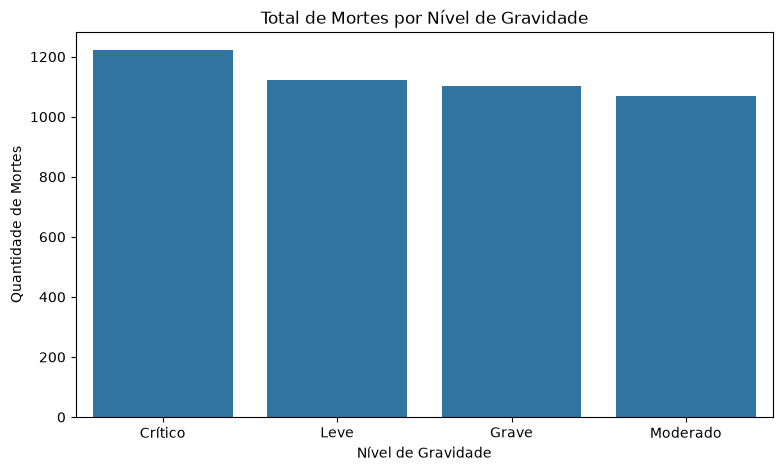

In [70]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=mortes_por_gravidade.index,
    y=mortes_por_gravidade.values
)

plt.title("Total de Mortes por Nível de Gravidade")
plt.xlabel("Nível de Gravidade")
plt.ylabel("Quantidade de Mortes")

plt.show()

### Interpretação — Mortes por nível de gravidade

A categoria Crítico apresentou o maior número de mortes na base analisada, totalizando 1.221 registros.

Em seguida aparecem as categorias Leve, com 1.124 mortes, Grave, com 1.101, e Moderado, com 1.069.

Embora a categoria Crítico apresente o maior total, observa-se que os valores de mortes estão relativamente próximos entre os diferentes níveis de gravidade. Dessa forma, não há uma concentração extremamente elevada de mortes em uma única categoria dentro da base simulada.

Esse resultado também indica a importância de analisar separadamente a quantidade de acidentes e a quantidade de mortes, pois uma categoria com mais acidentes não necessariamente apresenta, na mesma proporção, o maior número de mortes.

## 6. Indicadores-chave (KPIs)

Nesta etapa, são calculados os principais indicadores do projeto, sintetizando os resultados mais relevantes da análise.

Os KPIs serão utilizados posteriormente no dashboard interativo para apresentar, de forma rápida e objetiva, informações como o total de acidentes, total de mortes, estado com maior número de ocorrências, tipo de acidente predominante e período do dia com maior concentração de acidentes.

In [71]:
total_acidentes = df["acidentes"].sum()
total_mortes = df["mortes"].sum()

estado_mais_critico = (
    df.groupby("uf")["acidentes"]
      .sum()
      .idxmax()
)

tipo_predominante = (
    df.groupby("tipo_acidente")["acidentes"]
      .sum()
      .idxmax()
)

periodo_mais_critico = (
    df.groupby("periodo_dia")["acidentes"]
      .sum()
      .idxmax()
)

print("Total de acidentes:", total_acidentes)
print("Total de mortes:", total_mortes)
print("Estado com maior número de acidentes:", estado_mais_critico)
print("Tipo de acidente predominante:", tipo_predominante)
print("Período do dia com maior número de acidentes:", periodo_mais_critico)

Total de acidentes: 88547
Total de mortes: 4515
Estado com maior número de acidentes: RJ
Tipo de acidente predominante: Atropelamento
Período do dia com maior número de acidentes: Tarde


### 6.1 Índice médio de gravidade

Como a variável `nivel_gravidade` é categórica, foi criada uma escala numérica para permitir o cálculo de um indicador médio de gravidade.

As categorias foram representadas da seguinte forma:

- Leve = 1
- Moderado = 2
- Grave = 3
- Crítico = 4

O indicador foi calculado por meio de uma média ponderada pela quantidade de acidentes de cada registro, de forma que registros com maior número de acidentes tenham peso proporcional no resultado.

In [72]:
mapa_gravidade = {
    "Leve": 1,
    "Moderado": 2,
    "Grave": 3,
    "Crítico": 4
}

df["gravidade_num"] = df["nivel_gravidade"].map(mapa_gravidade)

In [76]:
taxa_media_gravidade = (
    (df["gravidade_num"] * df["acidentes"]).sum()
    / df["acidentes"].sum()
)

taxa_media_gravidade
print(f"Índice médio de gravidade: {taxa_media_gravidade:.2f}")

Índice médio de gravidade: 2.52


### Interpretação — Índice médio de gravidade

O índice médio de gravidade obtido foi de aproximadamente 2,52 em uma escala de 1 a 4.

Como os valores 2 e 3 representam, respectivamente, as categorias Moderado e Grave, o resultado posiciona a gravidade média dos acidentes entre esses dois níveis.

Esse indicador é uma medida construída especificamente para esta análise a partir da classificação existente na base e deve ser interpretado de acordo com a escala adotada.

## 7. Relação entre condições climáticas e acidentes

Nesta etapa, será investigada a possível relação entre o volume de chuva e a quantidade de acidentes registrados na base.

Para essa análise, será utilizado um gráfico de dispersão, que permite observar como duas variáveis numéricas se comportam em conjunto. Também será calculado o coeficiente de correlação entre o volume de chuva e a quantidade de acidentes.

### 7.1 Relação entre Volume de Chuva e Quantidade de Acidentes (Gráfico de dispersão)

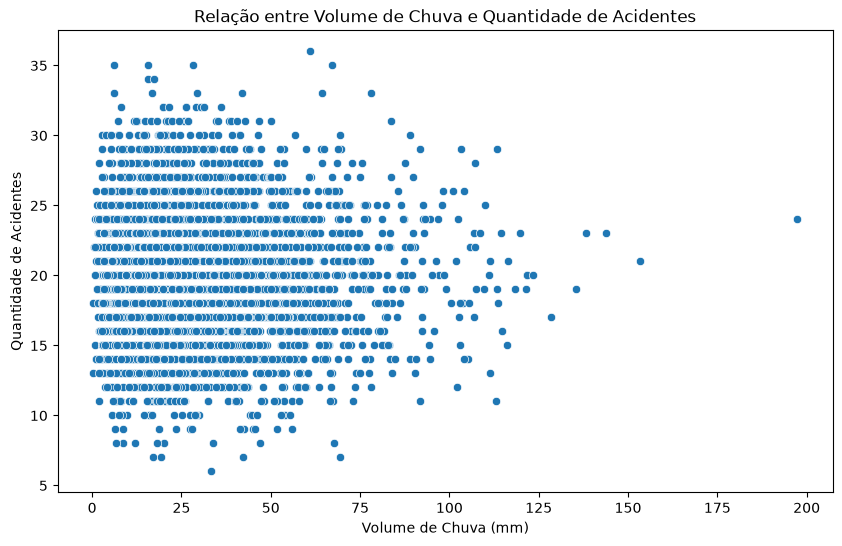

In [77]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="chuva_mm",
    y="acidentes"
)

plt.title("Relação entre Volume de Chuva e Quantidade de Acidentes")
plt.xlabel("Volume de Chuva (mm)")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### 7.2 Correlação entre chuva e acidentes

In [78]:
correlacao_chuva_acidentes = df["chuva_mm"].corr(df["acidentes"])

print(f"Correlação entre chuva e acidentes: {correlacao_chuva_acidentes:.3f}")

Correlação entre chuva e acidentes: -0.007


### Interpretação — Relação entre chuva e acidentes

O gráfico de dispersão não apresenta uma tendência visual clara entre o volume de chuva e a quantidade de acidentes.

O coeficiente de correlação calculado foi de aproximadamente -0,007, valor muito próximo de zero. Isso indica que, na base analisada, não foi identificada uma relação linear significativa entre o volume de chuva e a quantidade de acidentes.

Dessa forma, os dados não permitem afirmar que o aumento do volume de chuva esteja associado diretamente ao aumento ou à redução do número de acidentes.

É importante destacar que a ausência de correlação linear não significa necessariamente ausência de qualquer relação entre as variáveis. Outros fatores, como visibilidade, período do dia, tipo de acidente e quantidade de veículos envolvidos, também podem influenciar as ocorrências.

### 7.3 Relação entre visibilidade e acidentes
A visibilidade é uma condição que pode influenciar a segurança viária, principalmente em situações de chuva, neblina ou baixa iluminação.

Nesta análise, os acidentes são agrupados de acordo com as condições de visibilidade registradas na base, permitindo comparar a quantidade total de acidentes entre as diferentes categorias.

In [81]:
acidentes_por_visibilidade = (
    df.groupby("visibilidade")["acidentes"]
      .sum()
      .sort_values(ascending=False)
)

acidentes_por_visibilidade

visibilidade
Ruim          22594
Muito ruim    22566
Moderada      21806
Boa           21581
Name: acidentes, dtype: int64

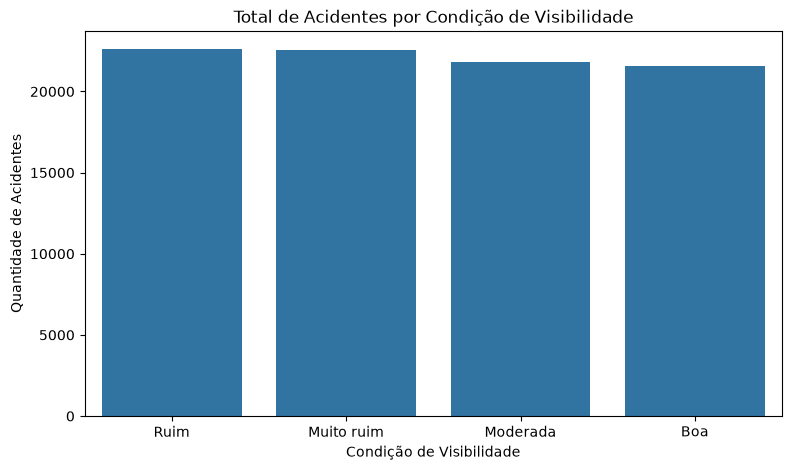

In [82]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=acidentes_por_visibilidade.index,
    y=acidentes_por_visibilidade.values
)

plt.title("Total de Acidentes por Condição de Visibilidade")
plt.xlabel("Condição de Visibilidade")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### Interpretação — Visibilidade e acidentes

A análise por condição de visibilidade mostra que a categoria Ruim apresentou o maior número de acidentes registrados na base, com 22.594 ocorrências, seguida muito de perto por Muito ruim, com 22.566.

As categorias Moderada e Boa apresentaram, respectivamente, 21.806 e 21.581 acidentes.

Apesar de as piores condições de visibilidade apresentarem os maiores totais, as diferenças entre as quatro categorias são relativamente pequenas. Dessa forma, os resultados não indicam uma concentração extremamente elevada de acidentes em apenas uma condição de visibilidade.

Também é importante destacar que esses valores representam totais absolutos da base e não permitem, isoladamente, concluir que determinada condição de visibilidade causa maior risco de acidente.

## 8. Análise de períodos críticos

### 8.1 Heatmap de acidentes por dia da semana e período do dia

Nesta análise, os acidentes são agrupados simultaneamente pelo dia da semana e pelo período do dia.
O objetivo é identificar combinações temporais com maior concentração de acidentes, permitindo observar padrões que não seriam percebidos ao analisar essas variáveis separadamente.

In [85]:
ordem_periodos = [
    "Madrugada",
    "Manhã",
    "Tarde",
    "Noite"
]

heatmap_periodos = heatmap_periodos.reindex(
    index=ordem_dias,
    columns=ordem_periodos
)

heatmap_periodos

periodo_dia,Madrugada,Manhã,Tarde,Noite
dia_semana,,,,
Segunda-feira,3126,3157,3174,3228
Terça-feira,2658,3029,3320,2790
Quarta-feira,3214,3158,3658,3391
Quinta-feira,3154,2917,2969,3259
Sexta-feira,3842,3049,3660,3381
Sábado,2505,2873,2639,3109
Domingo,3040,3395,3766,3086


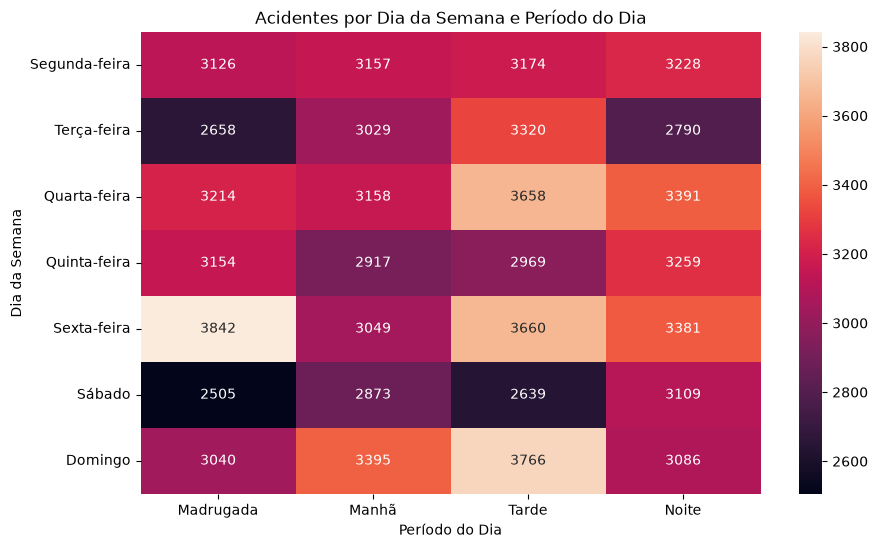

In [86]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_periodos,
    annot=True,
    fmt=".0f"
)

plt.title("Acidentes por Dia da Semana e Período do Dia")
plt.xlabel("Período do Dia")
plt.ylabel("Dia da Semana")

plt.show()

### Interpretação — Dia da semana e período do dia

O heatmap permite analisar conjuntamente o dia da semana e o período do dia, possibilitando identificar combinações temporais com maior concentração de acidentes.

A combinação com maior número de acidentes na base foi sexta-feira durante a madrugada, com 3.842 ocorrências. Também se destacam o domingo à tarde, com 3.766 acidentes, e a sexta-feira à tarde, com 3.660.

Por outro lado, o sábado durante a madrugada apresentou o menor total entre as combinações analisadas, com 2.505 acidentes.

Os resultados demonstram que a distribuição dos acidentes varia de acordo com a combinação entre dia da semana e período do dia. Essa análise complementa as avaliações realizadas anteriormente, pois permite identificar períodos críticos com maior nível de detalhe do que a análise isolada de cada variável.

### 8.2 Tabela dinâmica por região e tipo de acidente

Nesta análise, será criada uma tabela dinâmica relacionando as regiões do país com os tipos de acidente.

O objetivo é permitir uma comparação detalhada da quantidade de acidentes em cada combinação de região e tipo de ocorrência, facilitando a identificação de padrões que podem não ser percebidos em análises isoladas.

In [87]:
tabela_dinamica = pd.pivot_table(
    df,
    values="acidentes",
    index="regiao",
    columns="tipo_acidente",
    aggfunc="sum",
    margins=True,
    margins_name="Total"
)

tabela_dinamica

tipo_acidente,Atropelamento,Capotamento,Colisão,Saída de pista,Total
regiao,,,,,
Centro-Oeste,3302,2963,2767,3020,12052
Nordeste,4746,4840,5027,4594,19207
Norte,3401,2557,2835,3008,11801
Sudeste,8388,7439,7300,7927,31054
Sul,4063,3233,3616,3521,14433
Total,23900,21032,21545,22070,88547


### Interpretação — Tabela dinâmica por região e tipo de acidente

A tabela dinâmica permite comparar simultaneamente as regiões e os diferentes tipos de acidente.

A região Sudeste apresenta os maiores totais em todas as categorias analisadas, contribuindo para que também possua o maior número geral de acidentes da base, com 31.054 ocorrências.

Observa-se ainda que o tipo de acidente mais frequente não é necessariamente o mesmo em todas as regiões. No Nordeste, por exemplo, as colisões apresentam o maior total, enquanto no Norte predominam os atropelamentos.

A análise conjunta das duas variáveis permite identificar diferenças regionais na distribuição dos tipos de acidente, oferecendo uma visão mais detalhada do que as análises isoladas.

## 9. Fatores associados aos acidentes graves

Nesta etapa, serão analisadas algumas características dos acidentes classificados como Grave ou Crítico.

O objetivo é identificar padrões presentes entre as ocorrências de maior gravidade, considerando fatores como período do dia, visibilidade e tipo de acidente.

A análise busca identificar associações presentes na base, sem estabelecer relações de causalidade.

In [88]:
df_graves = df[
    df["nivel_gravidade"].isin(["Grave", "Crítico"])
]

In [89]:
df_graves.shape

(2269, 17)

In [90]:
df_graves["nivel_gravidade"].unique()

<ArrowStringArray>
['Crítico', 'Grave']
Length: 2, dtype: str

### 9.1 Comparação dos acidentes graves por fatores selecionados

Para investigar os fatores associados às ocorrências de maior gravidade, foram analisados os registros classificados como Grave ou Crítico.

A comparação considera o tipo de acidente, o período do dia e a condição de visibilidade, permitindo observar quais categorias concentram maiores quantidades de acidentes dentro desse subconjunto.

In [ ]:
graves_por_tipo = (
    df_graves.groupby("tipo_acidente")["acidentes"]
             .sum()
             .sort_values(ascending=False)
)

graves_por_tipo

tipo_acidente
Atropelamento     12058
Saída de pista    11317
Colisão           11150
Capotamento       10625
Name: acidentes, dtype: int64

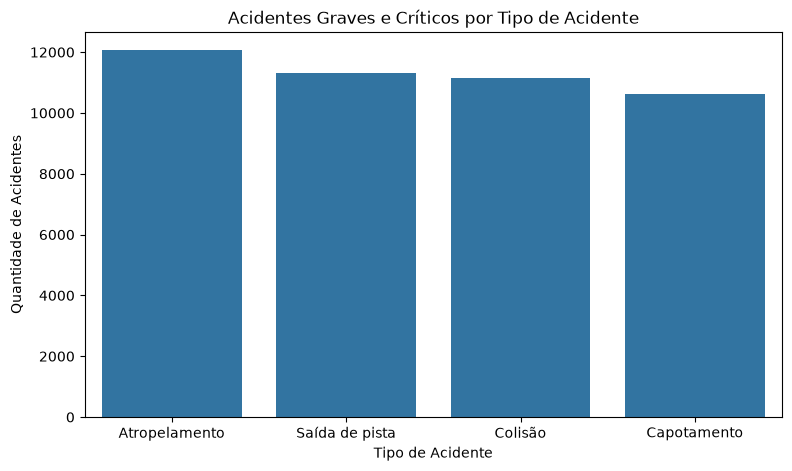

In [92]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=graves_por_tipo.index,
    y=graves_por_tipo.values
)

plt.title("Acidentes Graves e Críticos por Tipo de Acidente")
plt.xlabel("Tipo de Acidente")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### 9.2 Acidentes graves por período do dia

In [93]:
graves_por_periodo = (
    df_graves.groupby("periodo_dia")["acidentes"]
             .sum()
             .sort_values(ascending=False)
)

graves_por_periodo

periodo_dia
Noite        11892
Tarde        11341
Manhã        10966
Madrugada    10951
Name: acidentes, dtype: int64

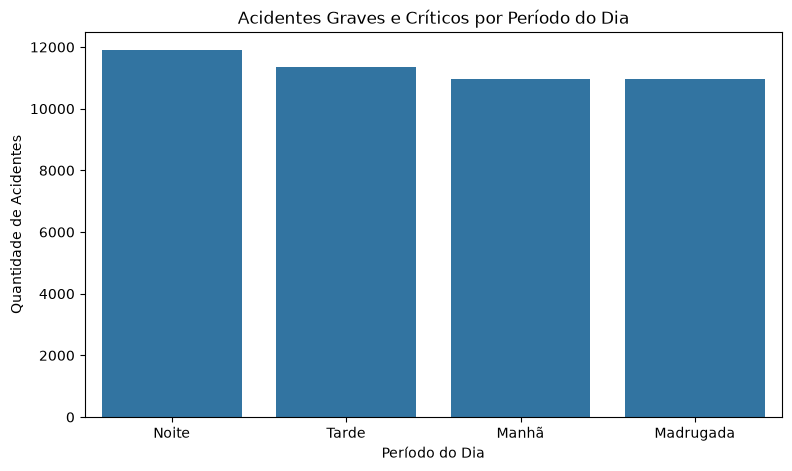

In [94]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=graves_por_periodo.index,
    y=graves_por_periodo.values
)

plt.title("Acidentes Graves e Críticos por Período do Dia")
plt.xlabel("Período do Dia")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### 9.3 Acidentes graves por condição de visibilidade

In [95]:
graves_por_visibilidade = (
    df_graves.groupby("visibilidade")["acidentes"]
             .sum()
             .sort_values(ascending=False)
)

graves_por_visibilidade

visibilidade
Muito ruim    12016
Boa           11673
Ruim          11198
Moderada      10263
Name: acidentes, dtype: int64

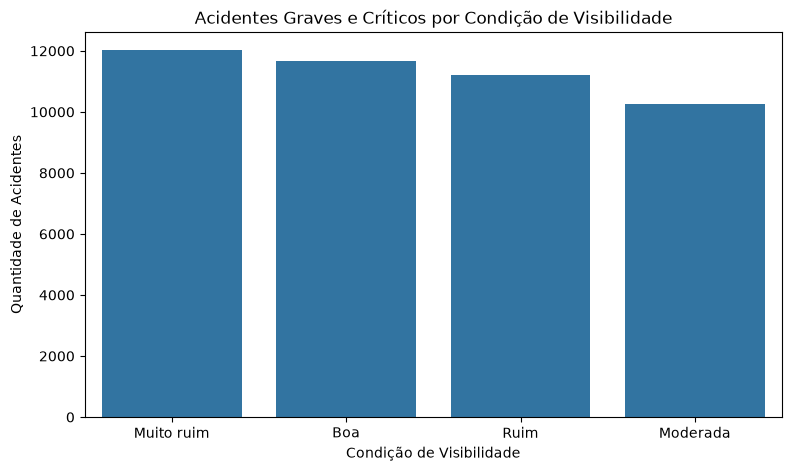

In [96]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=graves_por_visibilidade.index,
    y=graves_por_visibilidade.values
)

plt.title("Acidentes Graves e Críticos por Condição de Visibilidade")
plt.xlabel("Condição de Visibilidade")
plt.ylabel("Quantidade de Acidentes")

plt.show()

### Interpretação — Fatores associados aos acidentes graves

A análise dos registros classificados como Grave ou Crítico mostra que os atropelamentos apresentaram o maior número de acidentes nesse subconjunto, com 12.058 ocorrências. Em seguida aparecem as saídas de pista, com 11.317, as colisões, com 11.150, e os capotamentos, com 10.625.

Em relação ao período do dia, a noite apresentou o maior total de acidentes graves e críticos, com 11.892 ocorrências, seguida pela tarde, com 11.341. Já a madrugada apresentou o menor total entre os períodos analisados, com 10.951.

Quanto à visibilidade, a condição Muito ruim concentrou o maior número de acidentes graves e críticos, com 12.016 ocorrências. Na sequência aparecem Boa, com 11.673, Ruim, com 11.198, e Moderada, com 10.263.

Os resultados indicam que, dentro da base analisada, os acidentes graves e críticos aparecem com maior frequência entre atropelamentos, no período da noite e em condições de visibilidade muito ruim. Entretanto, essas diferenças devem ser interpretadas como associações presentes no conjunto de dados, e não como evidência de causalidade.

## 10. Síntese dos principais resultados

A análise exploratória permitiu identificar diferentes padrões relacionados aos acidentes de trânsito presentes na base simulada.

Entre os principais resultados observados, destacam-se:

- A região Sudeste apresentou o maior número de acidentes, com 31.054 ocorrências.
- O estado do Rio de Janeiro apresentou o maior total de acidentes, com 9.633 registros.
- O atropelamento foi o tipo de acidente mais frequente na base, totalizando 23.900 ocorrências.
- A tarde foi o período do dia com maior número total de acidentes, com 23.186 registros.
- A sexta-feira apresentou o maior número de acidentes entre os dias da semana, com 13.932 ocorrências.
- A evolução temporal entre 2015 e 2024 apresentou relativa estabilidade, sem tendência contínua de crescimento ou redução.
- A correlação entre volume de chuva e quantidade de acidentes foi de aproximadamente -0,007, indicando ausência de relação linear relevante entre essas variáveis.
- As condições de visibilidade Ruim e Muito ruim apresentaram os maiores totais de acidentes, embora os valores entre as categorias tenham permanecido relativamente próximos.
- No cruzamento entre dia da semana e período do dia, a combinação sexta-feira durante a madrugada apresentou o maior número de acidentes, com 3.842 ocorrências.
- Entre os registros classificados como Grave ou Crítico, os atropelamentos apresentaram o maior total, enquanto a noite foi o período com maior número dessas ocorrências e a condição de visibilidade Muito ruim concentrou o maior total nesse subconjunto.

## 11. Conclusão

O projeto teve como objetivo analisar padrões relacionados aos acidentes de trânsito no Brasil a partir de uma base de dados simulada referente ao período de 2015 a 2024.

A análise permitiu explorar diferentes dimensões das ocorrências, incluindo distribuição regional e estadual, tipos de acidente, períodos do dia, dias da semana, condições de visibilidade, volume de chuva, níveis de gravidade, feridos e mortes.

Os resultados mostraram maior concentração absoluta de acidentes na região Sudeste e no estado do Rio de Janeiro. Os atropelamentos foram o tipo de acidente mais frequente, enquanto a tarde apresentou o maior total de ocorrências entre os períodos do dia. Ao longo dos anos analisados, os números permaneceram relativamente estáveis, sem indicar uma tendência clara de crescimento ou redução.

A análise da relação entre chuva e acidentes apresentou correlação praticamente nula, indicando ausência de associação linear relevante entre essas variáveis na base. Por outro lado, a análise combinada de dia da semana e período do dia permitiu identificar sexta-feira durante a madrugada como a combinação com maior número de acidentes.

Também foram analisados os registros classificados como Grave ou Crítico, nos quais se destacaram os atropelamentos, o período da noite e a condição de visibilidade Muito ruim.

É importante ressaltar que os resultados obtidos representam exclusivamente os padrões presentes na base simulada utilizada e não devem ser interpretados como retrato definitivo da realidade dos acidentes de trânsito no Brasil. Além disso, as análises realizadas identificam associações entre variáveis, mas não permitem estabelecer relações de causalidade.

De modo geral, o projeto demonstrou como técnicas de tratamento, análise exploratória, visualização de dados e construção de indicadores podem ser utilizadas para transformar uma base de dados em informações mais claras e úteis para interpretação e apoio à tomada de decisão.